# Лабораторная работа № 1

## Однородные координаты и группа SE(3). Дерево систем координат

**Дисциплина:** Введение в технологии виртуальной дополненной реальности и робототехники
**Тема курса:** 2. Аффинная геометрия сцены. Однородные координаты и группа SE(3)

---

**Студент:** _фамилия, имя, группа_
**Дата:**

---

### Цель работы

Реализовать жёсткое преобразование трёхмерного пространства как элемент группы $SE(3)$,
проверить свойства группы численным экспериментом, построить дерево систем координат
и оценить накопление вычислительной погрешности при многократной композиции.

### Что понадобится

`numpy`, `matplotlib`. Ничего больше.

### Правило практикума

Алгоритм вы реализуете сами. Готовые функции из библиотек пространственных преобразований
(`scipy.spatial.transform`, `spatialmath`, `pytransform3d`) допустимо использовать **только**
для сверки собственного результата — и такую сверку нужно показать явно.

## Теоретическая справка

**Жёсткое преобразование** переводит точку $p \in \mathbb{R}^3$ в точку $Rp + t$, где
$R$ — матрица поворота, $t$ — вектор сдвига. Такое отображение не является линейным
(из-за сдвига), поэтому одной матрицей $3\times 3$ его не записать.

**Однородные координаты** решают эту проблему: точку $p = (x, y, z)$ представляют
четвёркой $(x, y, z, 1)$, а вектор (направление, разность точек) — четвёркой $(x, y, z, 0)$.
Тогда преобразование становится линейным и записывается матрицей $4\times4$:

$$
T \;=\;
\begin{pmatrix} R & t \\ 0^{\mathsf T} & 1 \end{pmatrix},
\qquad
R \in SO(3): \quad R^{\mathsf T} R = I, \;\; \det R = +1, \qquad t \in \mathbb{R}^3 .
$$

Множество таких матриц образует **группу** $SE(3)$ относительно умножения:

* композиция двух преобразований снова является преобразованием (замкнутость);
* умножение ассоциативно: $(AB)C = A(BC)$;
* нейтральный элемент — единичная матрица $I$;
* обратный элемент существует и вычисляется в замкнутой форме:

$$
T^{-1} = \begin{pmatrix} R^{\mathsf T} & -R^{\mathsf T} t \\ 0^{\mathsf T} & 1 \end{pmatrix}.
$$

Обратите внимание: обращать матрицу численно (`np.linalg.inv`) не нужно и не следует —
формула выше даёт точный результат за $O(1)$ операций.

Группа **некоммутативна**: $AB \ne BA$. Это не техническая деталь, а физический факт —
повернуть, а затем сдвинуть, и сдвинуть, а затем повернуть, приводит в разные точки.

**Дерево систем координат.** У робота каждое звено несёт свою систему координат, заданную
относительно родительской. Совокупность образует дерево с корнем в мировом кадре.
Преобразование между двумя произвольными кадрами получается перемножением матриц вдоль
пути через общего предка. Именно это делает библиотека TF2 в ROS.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

## Задание 1. Элементарные повороты и класс преобразования

Реализуйте три функции элементарных поворотов и класс `Transform`.

**Требования к классу:**

* хранит матрицу $4\times4$ в поле `M`;
* конструктор `from_Rt(R, t)`; по умолчанию — тождественное преобразование;
* свойства `R` и `t`;
* композиция через оператор `@` (метод `__matmul__`), возвращающая новый `Transform`;
* `inverse()` — **по формуле**, без `np.linalg.inv`;
* `apply_point(p)` и `apply_vector(v)`, работающие и с одной точкой, и с массивом точек $N\times3$.

*Подсказка по знакам:* поворот вокруг оси $z$ на угол $\alpha$ переводит орт $e_x$ в
$(\cos\alpha, \sin\alpha, 0)$.

In [3]:
import numpy as np

def rotx(a):
    return np.array([[1, 0, 0], [0, np.cos(a), -np.sin(a)], [0, np.sin(a), np.cos(a)]])


def roty(a):
    return np.array([[np.cos(a), 0, np.sin(a)], [0, 1, 0], [-np.sin(a), 0, np.cos(a)]])


def rotz(a):
    return np.array([[np.cos(a), -np.sin(a), 0], [np.sin(a), np.cos(a), 0], [0, 0, 1]])


class Transform:
    """Жёсткое преобразование как элемент SE(3), хранимое матрицей 4x4."""

    def __init__(self, matrix=None):
        self.M = np.eye(4) if matrix is None else np.asarray(matrix, dtype=float)
        if self.M.shape != (4, 4):
            raise ValueError('нужна матрица 4x4, получено %s' % (self.M.shape,))

    @classmethod
    def from_Rt(cls, R, t):
        R = np.asarray(R, dtype=float)
        t = np.asarray(t, dtype=float)
        if R.shape != (3, 3):
            raise ValueError(f'R должна быть 3x3, получено {R.shape}')
        if t.shape != (3,):
            t = t.flatten()
            if t.shape != (3,):
                raise ValueError(f't должен быть вектором длины 3, получено {t.shape}')
        
        M = np.eye(4) #единичная матрица 4x4
        M[:3, :3] = R
        M[:3, 3] = t
        return cls(M) #объект класса Transform

    @property
    def R(self):
        return self.M[:3, :3]

    @property
    def t(self):
        return self.M[:3, 3]

    def __matmul__(self, other):
        if not isinstance(other, Transform):
            return NotImplemented
        return Transform(self.M @ other.M)

    def inverse(self):
        M_inv = np.eye(4)
        M_inv[:3, :3] = self.R.T
        M_inv[:3, 3] = -self.R.T @ self.t
        return Transform(M_inv)

    def apply_point(self, p):
        p = np.asarray(p, dtype=float)
        original_shape = p.shape
        
        # Приводим к (N, 3) (трёхмерный массив из N точек)
        if p.ndim == 1: #степень вложенности (просто точка)
            p = p.reshape(1, -1) #пересобираем в матрицу с 1 строкой   #матрица с одной точкой ≠ одна точка
        elif p.ndim == 2:
            pass
        else:
            raise ValueError('p должен быть (3,) или (N, 3)')
        
        if p.shape[1] != 3:
            raise ValueError('последняя размерность должна быть 3')
        
        # Добавляем однородную координату w=1
        ones = np.ones((p.shape[0], 1))
        p_hom = np.hstack([p, ones])  # (N, 4)
        
        # Применяем преобразование
        result_hom = (self.M @ p_hom.T).T  # (N, 4)
        
        # Убираем однородную координату
        result = result_hom[:, :3]
        
        # Восстанавливаем исходную форму
        if original_shape == (3,): #если был дан набор точек
            return result[0]
        return result #если была дана одна точка

    def apply_vector(self, v):
        v = np.asarray(v, dtype=float)
        original_shape = v.shape
        
        # Приводим к (N, 3)
        if v.ndim == 1:
            v = v.reshape(1, -1)
        elif v.ndim == 2:
            pass
        else:
            raise ValueError('v должен быть (3,) или (N, 3)')
        
        if v.shape[1] != 3:
            raise ValueError('последняя размерность должна быть 3')
        
        # Добавляем однородную координату w=0
        zeros = np.zeros((v.shape[0], 1))
        v_hom = np.hstack([v, zeros])  # (N, 4)
        
        # Применяем преобразование
        result_hom = (self.M @ v_hom.T).T  # (N, 4)
        
        # Убираем однородную координату
        result = result_hom[:, :3]
        
        # Восстанавливаем исходную форму
        if original_shape == (3,):
            return result[0]
        return result

    def __repr__(self):
        return 'Transform(\n%s)' % np.array2string(self.M, precision=4, suppress_small=True)


**Проверка.** Ячейка ниже должна отработать без ошибок.

In [4]:
T = Transform.from_Rt(rotz(np.pi / 6) @ rotx(np.pi / 4), [1.0, -2.0, 0.5])
resid = np.linalg.norm((T @ T.inverse()).M - np.eye(4))
print('||T @ T^-1 - I|| = %.3e' % resid)
assert resid < 1e-12, 'обращение реализовано неверно'
print('OK')

||T @ T^-1 - I|| = 2.309e-16
OK


## Задание 2. Точка и вектор — в чём разница

Возьмите $p = (1, 0, 0)$ и примените к нему `apply_point` и `apply_vector`.

**Что показать в отчёте:** численно подтвердить, что сдвиг действует на точку и **не действует**
на вектор, то есть `apply_vector(p)` совпадает с $Rp$ с точностью до машинной погрешности.

**Вопрос для вывода:** какие физические величины следует преобразовывать как векторы,
а не как точки? Приведите два примера.

In [5]:
R = np.array([[0, -1, 0], [1, 0, 0], [0, 0, 1]]) #поворот на 90 градусов вокруг Z
t = np.array([10, 0, 0])

T = Transform.from_Rt(R, t)

point = np.array([0, 0, 0])
result = T.apply_point(point)
print(result)

vector = np.array([1, 0, 0])
result = T.apply_vector(vector)
print(result)

[10.  0.  0.]
[0. 1. 0.]


## Задание 3. Свойства группы — численная проверка

Напишите функцию `random_transform(rng)`, порождающую случайный элемент $SE(3)$
(случайные углы Эйлера и случайный сдвиг). Возьмите три случайных элемента $A$, $B$, $C$ и проверьте:

1. **ассоциативность:** $\|(AB)C - A(BC)\|$ — должно быть порядка $10^{-15}$;
2. **некоммутативность:** $\|AB - BA\|$ — должно быть **не** малым; приведите конкретный контрпример;
3. **замкнутость:** для произведения $AB$ проверьте $\|R^{\mathsf T}R - I\|$ и $\det R$.

**Вопрос для вывода:** почему проверка ассоциативности даёт не ноль, а $10^{-15}$?
Что именно измеряет эта величина?

In [6]:
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)


def random_transform(rng):
    """
    Создаёт случайный элемент SE(3).
    Использует случайные углы Эйлера и случайный сдвиг.
    """
    # Случайные углы
    alpha = rng.uniform(-np.pi, np.pi)
    beta = rng.uniform(-np.pi, np.pi)
    gamma = rng.uniform(-np.pi, np.pi)
    
    # Случайный сдвиг в диапазоне [-5, 5]
    t = rng.uniform(-5, 5, 3)
    
    # Матрица поворота
    R = rotz(alpha) @ roty(beta) @ rotx(gamma)
    
    return Transform.from_Rt(R, t)


# Генерируем три случайных преобразования
A = random_transform(rng)
B = random_transform(rng)
C = random_transform(rng)

print("=== Сгенерированные преобразования ===")
print("A:")
print(A)
print("\nB:")
print(B)
print("\nC:")
print(C)


# 1. Проверка ассоциативности: (AB)C = A(BC)
print("\n" + "="*60)
print("1. Проверка ассоциативности: (AB)C = A(BC)")

AB = A @ B
BC = B @ C

left = (AB) @ C   # (A @ B) @ C
right = A @ (BC)  # A @ (B @ C)

# Сравниваем матрицы
diff_asso = np.linalg.norm(left.M - right.M)
print(f"||(AB)C - A(BC)|| = {diff_asso:.3e}")

# Проверяем, что это близко к машинной точности
eps = np.finfo(float).eps
if diff_asso < 1e-12:
    print("Ассоциативность выполняется с точностью до машинной погрешности")
else:
    print("Погрешность больше ожидаемой")


# 2. Проверка некоммутативности: AB ≠ BA
print("\n" + "="*60)
print("2. Проверка некоммутативности: AB ≠ BA")

AB = A @ B
BA = B @ A

diff_comm = np.linalg.norm(AB.M - BA.M)
print(f"||AB - BA|| = {diff_comm:.3e}")

if diff_comm > 1e-3:
    print("Группа некоммутативна (AB ≠ BA)")
    print(f"   Разница значительная: {diff_comm:.3e}")
else:
    print("Преобразования случайно оказались близкими к коммутирующим")

# Показываем конкретный контрпример (разницу в координатах точки)
p_test = np.array([1.0, 0.0, 0.0])
p_AB = AB.apply_point(p_test)
p_BA = BA.apply_point(p_test)
diff_point = np.linalg.norm(p_AB - p_BA)

print(f"\nКонтрпример на точке p = (1, 0, 0):")
print(f"  (AB)·p = {p_AB}")
print(f"  (BA)·p = {p_BA}")
print(f"  ||(AB)·p - (BA)·p|| = {diff_point:.3e}")


# 3. Проверка замкнутости: произведение AB ∈ SE(3)
print("\n" + "="*60)
print("3. Проверка замкнутости: произведение AB ∈ SE(3)")

AB = A @ B
R_AB = AB.R

# Проверка ортогональности: R^T · R = I
orth_error = np.linalg.norm(R_AB.T @ R_AB - np.eye(3))
print(f"||R^T·R - I|| = {orth_error:.3e}")

# Проверка определителя: det(R) = 1
det_R = np.linalg.det(R_AB)
print(f"det(R) = {det_R:.6f}")

if orth_error < 1e-12 and abs(det_R - 1.0) < 1e-12:
    print("Произведение AB является корректным элементом SE(3)")
    print("   (R ортогональна, det(R) = 1)")
else:
    print("Произведение не является идеальным элементом SE(3)")

=== Сгенерированные преобразования ===
A:
Transform(
[[-0.139   0.6671  0.7319  1.9737]
 [ 0.9167 -0.1929  0.35   -4.0582]
 [ 0.3747  0.7196 -0.5847  4.7562]
 [ 0.      0.      0.      1.    ]])

B:
Transform(
[[ 0.0157  0.7406 -0.6718 -0.4961]
 [-0.2241 -0.6522 -0.7242 -1.292 ]
 [-0.9744  0.1619  0.1557  4.2676]
 [ 0.      0.      0.      1.    ]])

C:
Transform(
[[-0.273  -0.9298  0.2468 -2.7276]
 [-0.3468  0.3344  0.8763  0.5458]
 [-0.8973  0.1537 -0.4138 -4.3618]
 [ 0.      0.      0.      1.    ]])

1. Проверка ассоциативности: (AB)C = A(BC)
||(AB)C - A(BC)|| = 1.367e-15
Ассоциативность выполняется с точностью до машинной погрешности

2. Проверка некоммутативности: AB ≠ BA
||AB - BA|| = 1.128e+01
Группа некоммутативна (AB ≠ BA)
   Разница значительная: 1.128e+01

Контрпример на точке p = (1, 0, 0):
  (AB)·p = [ 3.4394 -3.0536  1.5598]
  (BA)·p = [-6.2408 -3.37    2.7702]
  ||(AB)·p - (BA)·p|| = 9.761e+00

3. Проверка замкнутости: произведение AB ∈ SE(3)
||R^T·R - I|| = 3.790e-16
d

## Задание 4. Дерево систем координат

Ниже задано дерево кадров робота с камерой на схвате и столом с объектом:

```
world ─┬─ base ── shoulder ── elbow ── wrist ── camera
       └─ table ── object
```

Реализуйте три функции:

* `chain_to_root(frame)` — список кадров от заданного до корня;
* `world_from(frame)` — преобразование из кадра `frame` в мировой;
* `lookup(target, source)` — преобразование, переводящее координаты **из** `source` **в** `target`.

Это в точности то, что делает `tf2` в ROS: `lookup_transform(target, source)`.

**Что вычислить:** положение начала кадра `object` в системе координат `camera`.

**Две проверки, которые обязаны пройти:**

1. $\mathrm{lookup}(a,b)\cdot\mathrm{lookup}(b,a) = I$;
2. результат, полученный через `lookup`, совпадает с результатом пересчёта «вручную» через мировой кадр.

In [8]:
PARENT = {'base': 'world', 'table': 'world', 'shoulder': 'base', 'elbow': 'shoulder',
          'wrist': 'elbow', 'camera': 'wrist', 'object': 'table'}

LOCAL = {
    'base':     Transform.from_Rt(rotz(0.30), [0.00, 0.00, 0.20]),
    'table':    Transform.from_Rt(np.eye(3),  [1.20, 0.40, 0.00]),
    'shoulder': Transform.from_Rt(roty(0.45), [0.00, 0.00, 0.35]),
    'elbow':    Transform.from_Rt(roty(-0.80), [0.40, 0.00, 0.00]),
    'wrist':    Transform.from_Rt(rotx(0.60), [0.35, 0.00, 0.00]),
    'camera':   Transform.from_Rt(rotz(-np.pi / 2) @ roty(np.pi / 2), [0.05, 0.00, 0.10]),
    'object':   Transform.from_Rt(rotz(1.10), [0.10, -0.15, 0.75]),
}


def chain_to_root(frame):
    chain = []
    current = frame
    while current in PARENT:  # пока есть родитель
        chain.append(current)
        current = PARENT[current]
    chain.append(current)  # добавляем корень (world)
    return chain


# ----------------------------------------------------------------------------
# 4.2. Функция world_from(frame)
# ----------------------------------------------------------------------------

def world_from(frame):
    """
    Возвращает преобразование из кадра frame в мировой кадр (world).
    T_world_frame = T_world_parent · T_parent_grandparent · ... · T_frame_parent
    """
    if frame == 'world':
        return Transform()  # единичная матрица
    
    # Получаем цепочку от frame до корня
    chain = chain_to_root(frame)
    # chain = ['frame', 'parent', ..., 'world']
    # Нам нужны преобразования вдоль цепи
    # T_world_frame = T_world_parent @ T_parent_grandparent @ ... @ T_frame_parent
    
    result = Transform()  # начинаем с единичной матрицы
    # Идём от корня к frame (в обратном порядке)
    # chain = ['camera', 'wrist', 'elbow', 'shoulder', 'base', 'world']
    # Нужно перемножить: LOCAL['world'] @ LOCAL['base'] @ LOCAL['shoulder'] @ ...
    # Но LOCAL не содержит 'world', поэтому начинаем со следующего
    
    # Идём от frame к корню и собираем преобразования
    transforms = []
    current = frame
    while current in PARENT:
        transforms.append(LOCAL[current])  # добавляем локальное преобразование
        current = PARENT[current]
    # transforms = [LOCAL[frame], LOCAL[parent], ..., LOCAL[child_of_world]]
    
    # Перемножаем в правильном порядке: от корня к frame
    # T_world_frame = T_world_parent @ T_parent_grandparent @ ... @ T_frame_parent
    result = Transform()
    for T in reversed(transforms):
        result = result @ T  # применяем преобразования от корня к frame
    
    return result


# ----------------------------------------------------------------------------
# 4.3. Функция lookup(target, source)
# ----------------------------------------------------------------------------

def lookup(target, source):
    """
    Возвращает преобразование из системы координат source в target.
    T_target_source = T_target_world @ T_world_source
    где T_target_world = inverse(T_world_target)
    """
    if target == source:
        return Transform()  # если один и тот же кадр — единичное преобразование
    
    T_world_target = world_from(target)
    T_world_source = world_from(source)
    
    # T_target_source = T_target_world @ T_world_source
    # T_target_world = inverse(T_world_target)
    T_target_world = T_world_target.inverse()
    
    return T_target_world @ T_world_source

In [9]:
# ============================================================================
# Проверка 1: lookup(a,b) @ lookup(b,a) = I
# ============================================================================

print("\n" + "-" * 70)
print("Проверка 1: lookup(a,b) @ lookup(b,a) = I")

# Проверяем для всех пар кадров
frames = list(PARENT.keys()) + ['world']
errors = []

for a in frames:
    for b in frames:
        Tab = lookup(a, b)
        Tba = lookup(b, a)
        product = Tab @ Tba
        error = np.linalg.norm(product.M - np.eye(4))
        errors.append(error)

max_error = max(errors)
print(f"Максимальная ошибка ||lookup(a,b)@lookup(b,a) - I|| = {max_error:.3e}")

if max_error < 1e-12:
    print("Проверка пройдена! Все преобразования взаимно обратны.")
else:
    print(f"Ошибка больше ожидаемой: {max_error:.3e}")


# ============================================================================
# Проверка 2: результат через lookup совпадает с ручным пересчётом
# ============================================================================

print("\n" + "-" * 70)
print("Проверка 2: результат через lookup совпадает с ручным пересчётом")

# Ручной пересчёт: T_camera_object = inverse(T_world_camera) @ T_world_object
T_world_camera = world_from('camera')
T_world_object = world_from('object')
T_camera_object_manual = T_world_camera.inverse() @ T_world_object

# Сравниваем с lookup
T_camera_object_lookup = lookup('camera', 'object')
diff = np.linalg.norm(T_camera_object_lookup.M - T_camera_object_manual.M)

print(f"Разница между lookup и ручным пересчётом: {diff:.3e}")

# Проверяем положение точки
origin = np.array([0.0, 0.0, 0.0])
p_lookup = T_camera_object_lookup.apply_point(origin)
p_manual = T_camera_object_manual.apply_point(origin)
point_diff = np.linalg.norm(p_lookup - p_manual)

print(f"Положение object в camera через lookup: {p_lookup}")
print(f"Положение object в camera вручную:      {p_manual}")
print(f"Разница в положении точки: {point_diff:.3e}")

if diff < 1e-12:
    print("Проверка пройдена! Результаты совпадают.")
else:
    print(f"Результаты отличаются: {diff:.3e}")


----------------------------------------------------------------------
Проверка 1: lookup(a,b) @ lookup(b,a) = I
Максимальная ошибка ||lookup(a,b)@lookup(b,a) - I|| = 4.661e-16
Проверка пройдена! Все преобразования взаимно обратны.

----------------------------------------------------------------------
Проверка 2: результат через lookup совпадает с ручным пересчётом
Разница между lookup и ручным пересчётом: 0.000e+00
Положение object в camera через lookup: [-0.0016  0.6259  0.1066]
Положение object в camera вручную:      [-0.0016  0.6259  0.1066]
Разница в положении точки: 0.000e+00
Проверка пройдена! Результаты совпадают.


## Задание 5. Визуализация дерева координат

Постройте трёхмерный рисунок: для каждого кадра нарисуйте координатный триэдр
(три отрезка длиной ~0,18 из начала кадра вдоль его осей, разными цветами) и подпишите имя кадра.

Оси стройте **через `apply_point`** — это заодно проверяет корректность класса.

**Что показать в отчёте:** рисунок и словесное объяснение, почему кадр `camera` повёрнут
относительно `wrist` именно так.

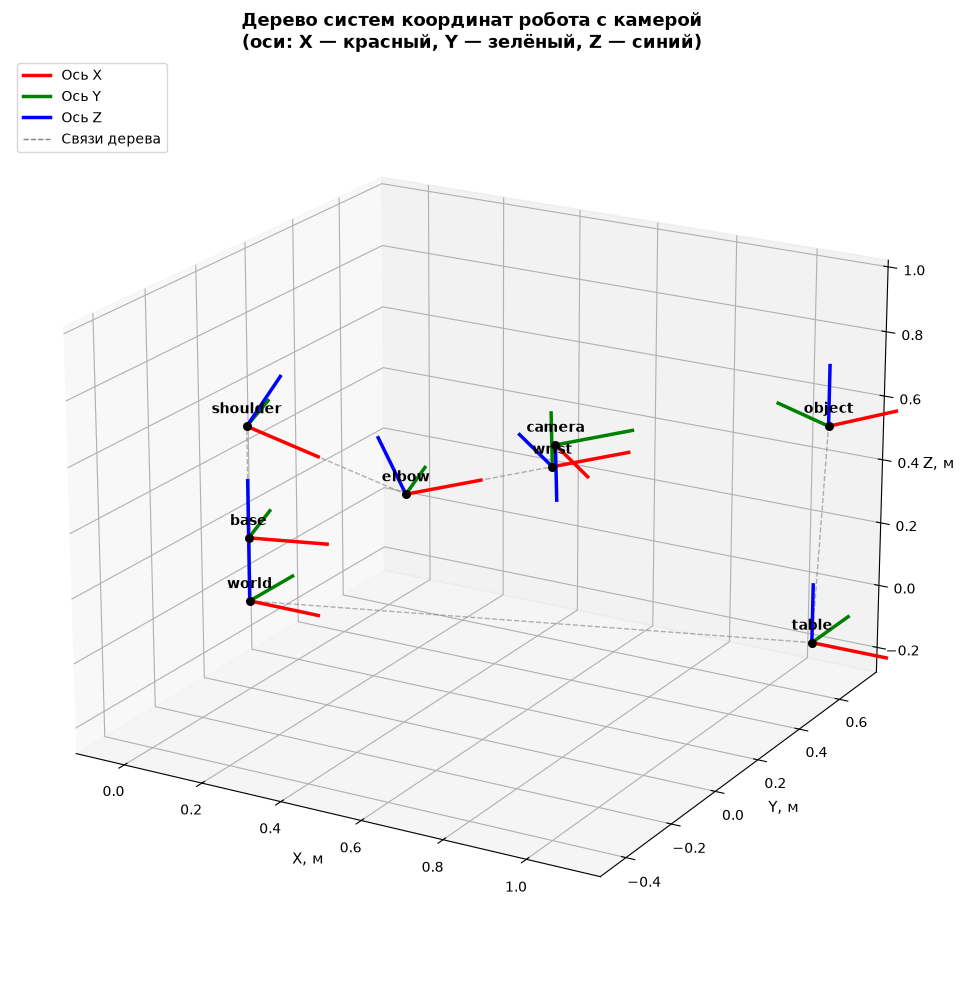

Рисунок сохранён в файл 'frame_tree.png'

Положения кадров в мировых координатах:
  world     : начало = (+0.000, +0.000, +0.000)
  base      : начало = (+0.000, +0.000, +0.200)
  table     : начало = (+1.200, +0.400, +0.000)
  shoulder  : начало = (+0.000, +0.000, +0.550)
  elbow     : начало = (+0.344, +0.106, +0.376)
  wrist     : начало = (+0.658, +0.204, +0.496)
  camera    : начало = (+0.693, +0.155, +0.591)
  object    : начало = (+1.300, +0.250, +0.750)

Ориентации кадров (направления осей в мировых координатах):
  world     :
      X_local → (+1.000, +0.000, +0.000)
      Y_local → (+0.000, +1.000, +0.000)
      Z_local → (+0.000, +0.000, +1.000)
  base      :
      X_local → (+0.955, +0.296, +0.000)
      Y_local → (-0.296, +0.955, +0.000)
      Z_local → (+0.000, +0.000, +1.000)
  table     :
      X_local → (+1.000, +0.000, +0.000)
      Y_local → (+0.000, +1.000, +0.000)
      Z_local → (+0.000, +0.000, +1.000)
  shoulder  :
      X_local → (+0.860, +0.266, -0.435)
      Y

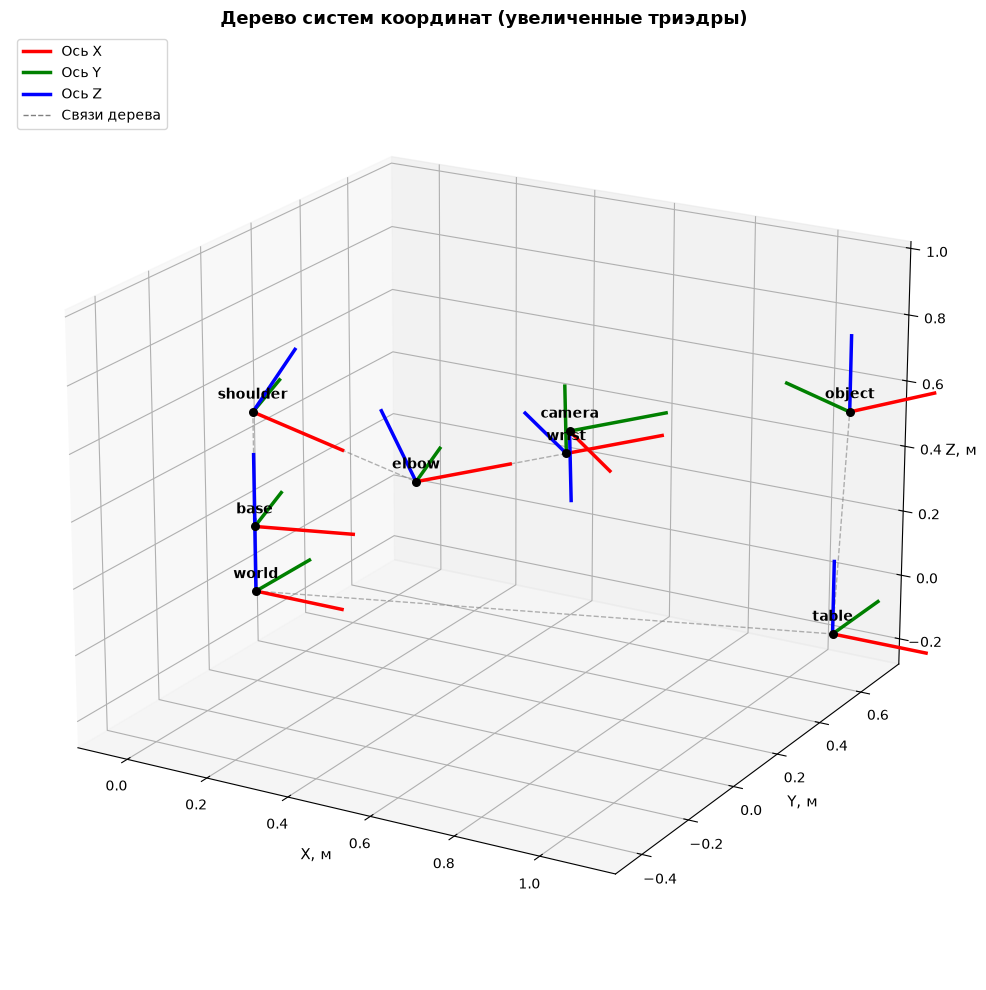

In [10]:
from mpl_toolkits.mplot3d import Axes3D
from mpl_toolkits.mplot3d.art3d import Line3DCollection

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)

# ============================================================================
# Задание 5: Визуализация дерева координат
# ============================================================================

# Все кадры, включая мировой
ALL_FRAMES = ['world'] + list(PARENT.keys())

# Цвета для осей X, Y, Z (RGB)
AXIS_COLORS = ['red', 'green', 'blue']
AXIS_LABELS = ['X', 'Y', 'Z']

# Длина осей на рисунке
AXIS_LENGTH = 0.18


def draw_frame(ax, T_world_frame, name, axis_length=AXIS_LENGTH):
    """
    Рисует координатный триэдр для кадра.
    
    T_world_frame: преобразование из кадра в мировой
    name: имя кадра (для подписи)
    axis_length: длина осей
    """
    # Начало кадра в мировых координатах
    origin = T_world_frame.apply_point(np.array([0.0, 0.0, 0.0]))
    
    # Концы осей: используем apply_point!
    # Точка (axis_length, 0, 0) в кадре → в мировых координатах
    x_end = T_world_frame.apply_point(np.array([axis_length, 0.0, 0.0]))
    y_end = T_world_frame.apply_point(np.array([0.0, axis_length, 0.0]))
    z_end = T_world_frame.apply_point(np.array([0.0, 0.0, axis_length]))
    
    # Рисуем три отрезка
    for end, color in zip([x_end, y_end, z_end], AXIS_COLORS):
        ax.plot([origin[0], end[0]],
                [origin[1], end[1]],
                [origin[2], end[2]],
                color=color, linewidth=2.5)
    
    # Рисуем точку в начале кадра
    ax.scatter(*origin, color='black', s=30, zorder=5)
    
    # Подписываем кадр
    ax.text(origin[0], origin[1], origin[2] + 0.03, name,
            fontsize=10, fontweight='bold', color='black',
            ha='center', va='bottom')


def draw_tree_connections(ax, parent, world_transforms):
    """Рисует линии, соединяющие кадры (структуру дерева)."""
    for child, p in parent.items():
        if p in world_transforms:
            child_pos = world_transforms[child].apply_point(np.array([0.0, 0.0, 0.0]))
            parent_pos = world_transforms[p].apply_point(np.array([0.0, 0.0, 0.0]))
            
            ax.plot([parent_pos[0], child_pos[0]],
                    [parent_pos[1], child_pos[1]],
                    [parent_pos[2], child_pos[2]],
                    color='gray', linewidth=1.0, linestyle='--', alpha=0.6)


# Вычисляем мировые преобразования для всех кадров
world_transforms = {frame: world_from(frame) for frame in ALL_FRAMES}


# ============================================================================
# Создаём трёхмерный рисунок
# ============================================================================

fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')

# Рисуем связи между кадрами (под триэдрами)
draw_tree_connections(ax, PARENT, world_transforms)

# Рисуем триэдр для каждого кадра
for frame in ALL_FRAMES:
    draw_frame(ax, world_transforms[frame], frame)

# Настраиваем оси
ax.set_xlabel('X, м', fontsize=11)
ax.set_ylabel('Y, м', fontsize=11)
ax.set_zlabel('Z, м', fontsize=11)
ax.set_title('Дерево систем координат робота с камерой\n'
             '(оси: X — красный, Y — зелёный, Z — синий)',
             fontsize=13, fontweight='bold')

# Равный масштаб по осям
all_points = np.array([
    world_transforms[f].apply_point(np.array([0.0, 0.0, 0.0]))
    for f in ALL_FRAMES
])
max_range = np.ptp(all_points, axis=0).max() / 2.0
mid = all_points.mean(axis=0)
ax.set_xlim(mid[0] - max_range, mid[0] + max_range)
ax.set_ylim(mid[1] - max_range, mid[1] + max_range)
ax.set_zlim(mid[2] - max_range, mid[2] + max_range)

# Легенда для цветов осей
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color='red', lw=2.5, label='Ось X'),
    Line2D([0], [0], color='green', lw=2.5, label='Ось Y'),
    Line2D([0], [0], color='blue', lw=2.5, label='Ось Z'),
    Line2D([0], [0], color='gray', lw=1.0, linestyle='--', label='Связи дерева'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=10)

# Хороший угол обзора
ax.view_init(elev=20, azim=-60)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('frame_tree.png', dpi=120, bbox_inches='tight')
plt.show()

print("Рисунок сохранён в файл 'frame_tree.png'")

# ============================================================================
# Дополнительно: положения кадров и их ориентации
# ============================================================================

print("\n" + "=" * 70)
print("Положения кадров в мировых координатах:")
print("=" * 70)

for frame in ALL_FRAMES:
    T = world_transforms[frame]
    pos = T.apply_point(np.array([0.0, 0.0, 0.0]))
    print(f"  {frame:10}: начало = ({pos[0]:+.3f}, {pos[1]:+.3f}, {pos[2]:+.3f})")

print("\n" + "=" * 70)
print("Ориентации кадров (направления осей в мировых координатах):")
print("=" * 70)

for frame in ALL_FRAMES:
    T = world_transforms[frame]
    # Оси кадра в мировых координатах — это столбцы матрицы R
    x_axis = T.apply_vector(np.array([1.0, 0.0, 0.0]))
    y_axis = T.apply_vector(np.array([0.0, 1.0, 0.0]))
    z_axis = T.apply_vector(np.array([0.0, 0.0, 1.0]))
    print(f"  {frame:10}:")
    print(f"      X_local → ({x_axis[0]:+.3f}, {x_axis[1]:+.3f}, {x_axis[2]:+.3f})")
    print(f"      Y_local → ({y_axis[0]:+.3f}, {y_axis[1]:+.3f}, {y_axis[2]:+.3f})")
    print(f"      Z_local → ({z_axis[0]:+.3f}, {z_axis[1]:+.3f}, {z_axis[2]:+.3f})")

# ============================================================================
# Отдельный рисунок: сравнение кадров wrist и camera
# ============================================================================

print("\n" + "=" * 70)
print("Анализ поворота camera относительно wrist:")
print("=" * 70)

T_camera = LOCAL['camera']
print("\nЛокальное преобразование camera (относительно wrist):")
print("R_camera =")
print(T_camera.R)
print(f"\nt_camera = {T_camera.t}")

print("\nЧто это означает:")
print("  R = rotz(-π/2) @ roty(π/2)")
print("  - Сначала поворот на +90° вокруг Y (roty(π/2))")
print("  - Затем поворот на -90° вокруг Z (rotz(-π/2))")
print("\n  Проверим, куда направлены оси camera в системе wrist:")
x_cam = T_camera.apply_vector(np.array([1.0, 0.0, 0.0]))
y_cam = T_camera.apply_vector(np.array([0.0, 1.0, 0.0]))
z_cam = T_camera.apply_vector(np.array([0.0, 0.0, 1.0]))
print(f"  X_camera в wrist: ({x_cam[0]:+.3f}, {x_cam[1]:+.3f}, {x_cam[2]:+.3f})")
print(f"  Y_camera в wrist: ({y_cam[0]:+.3f}, {y_cam[1]:+.3f}, {y_cam[2]:+.3f})")
print(f"  Z_camera в wrist: ({z_cam[0]:+.3f}, {z_cam[1]:+.3f}, {z_cam[2]:+.3f})")


# ============================================================================
# Второй рисунок: только локальные оси каждого кадра с относительными связями
# ============================================================================

fig2 = plt.figure(figsize=(14, 10))
ax2 = fig2.add_subplot(111, projection='3d')

# Рисуем связи между кадрами
draw_tree_connections(ax2, PARENT, world_transforms)

# Рисуем триэдры с увеличенной длиной осей
for frame in ALL_FRAMES:
    draw_frame(ax2, world_transforms[frame], frame, axis_length=0.22)

ax2.set_xlabel('X, м', fontsize=11)
ax2.set_ylabel('Y, м', fontsize=11)
ax2.set_zlabel('Z, м', fontsize=11)
ax2.set_title('Дерево систем координат (увеличенные триэдры)',
              fontsize=13, fontweight='bold')

# Равный масштаб
ax2.set_xlim(mid[0] - max_range, mid[0] + max_range)
ax2.set_ylim(mid[1] - max_range, mid[1] + max_range)
ax2.set_zlim(mid[2] - max_range, mid[2] + max_range)

ax2.legend(handles=legend_elements, loc='upper left', fontsize=10)
ax2.view_init(elev=20, azim=-60)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('frame_tree_large.png', dpi=120, bbox_inches='tight')
plt.show()

## Задание 6. Накопление погрешности

Возьмите преобразование малого шага `Tstep` (поворот порядка $10^{-3}$ рад и сдвиг порядка $10^{-3}$).
Для набора значений $N$ (логарифмическая сетка от $10$ до $10^5$):

1. умножьте тождественное преобразование на `Tstep` ровно $N$ раз;
2. затем умножьте результат на `Tstep.inverse()` тоже $N$ раз;
3. теоретически должна получиться единичная матрица — измерьте $\|T_{\text{acc}} - I\|$;
4. отдельно измерьте потерю ортогональности $\|R^{\mathsf T}R - I\|$.

Постройте оба графика в двойном логарифмическом масштабе и оцените наклон
(`np.polyfit` по логарифмам).

**Вопросы для вывода:**

* Какому наклону соответствует накопление погрешности, пропорциональное $N$? А пропорциональное $\sqrt N$?
* Какой наклон получился у вас и что это означает: ошибки накапливаются независимо или систематически?
* Оцените результат в единицах машинного эпсилон (`np.finfo(float).eps`). Опасна ли такая
  погрешность для робота с рабочей зоной в 1 метр?


Преобразование малого шага Tstep:
Transform(
[[ 1.     -0.001   0.0005  0.001 ]
 [ 0.001   1.     -0.0003  0.0007]
 [-0.0005  0.0003  1.     -0.0005]
 [ 0.      0.      0.      1.    ]])

Угол поворота: ~1.0e-03 рад
Сдвиг: ~1.0e-03 м
Машинный эпсилон: 2.220e-16

Количество значений N: 25
Диапазон N: от 10 до 100000

Вычисление...
       N |      ||T-I|| |   ||R^T R - I|| |     det(R)
------------------------------------------------------------
      10 |    4.172e-15 |       8.344e-15 |   1.000000
      15 |    5.933e-15 |       1.187e-14 |   1.000000
      22 |    8.751e-15 |       1.750e-14 |   1.000000
      32 |    1.255e-14 |       2.510e-14 |   1.000000
      46 |    1.849e-14 |       3.697e-14 |   1.000000
      68 |    2.728e-14 |       5.455e-14 |   1.000000
     100 |    4.028e-14 |       8.051e-14 |   1.000000
     147 |    5.861e-14 |       1.171e-13 |   1.000000
     215 |    8.520e-14 |       1.700e-13 |   1.000000
     316 |    1.243e-13 |       2.475e-13 |   1.000000
 

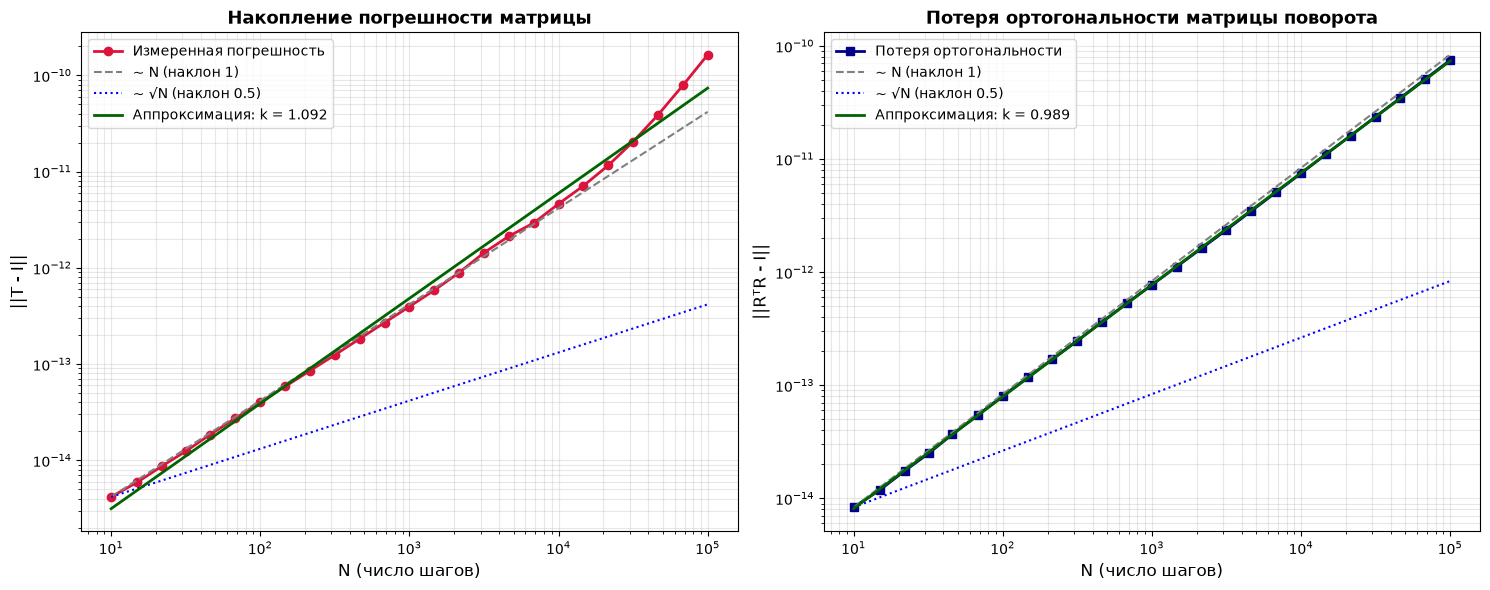


Рисунок сохранён в файл 'error_accumulation.png'

Сравнение с машинным эпсилон:
Машинный эпсилон: eps = 2.220e-16

Отношение погрешности к eps:
       N |     ||T-I||/eps |    ||R^T R-I||/eps
--------------------------------------------------
      10 |           18.79 |              37.58
      15 |           26.72 |              53.44
      22 |           39.41 |              78.82
      32 |           56.53 |             113.05
      46 |           83.26 |             166.50
      68 |          122.86 |             245.65
     100 |          181.40 |             362.60
     147 |          263.94 |             527.31
     215 |          383.70 |             765.77
     316 |          559.58 |            1114.58
     464 |          824.81 |            1636.00
     681 |         1214.38 |            2393.59
    1000 |         1781.56 |            3471.28
    1468 |         2633.83 |            5037.87
    2154 |         4014.12 |            7309.19
    3162 |         6460.12 |        

In [11]:
# ----------------------------------------------------------------------------
# 6.1. Преобразование малого шага
# ----------------------------------------------------------------------------

# Поворот порядка 10⁻³ рад и сдвиг порядка 10⁻³
STEP_ANGLE = 1e-3
STEP_TRANSLATION = 1e-3

Tstep = Transform.from_Rt(
    rotz(STEP_ANGLE) @ roty(0.5 * STEP_ANGLE) @ rotx(0.3 * STEP_ANGLE),
    [STEP_TRANSLATION, 0.7 * STEP_TRANSLATION, -0.5 * STEP_TRANSLATION]
)

print("\nПреобразование малого шага Tstep:")
print(Tstep)
print(f"\nУгол поворота: ~{STEP_ANGLE:.1e} рад")
print(f"Сдвиг: ~{STEP_TRANSLATION:.1e} м")
print(f"Машинный эпсилон: {np.finfo(float).eps:.3e}")


# ----------------------------------------------------------------------------
# 6.2. Сетка значений N (логарифмическая)
# ----------------------------------------------------------------------------

# Логарифмическая сетка от 10 до 10^5
N_values = np.unique(np.round(np.logspace(1, 5, 25)).astype(int))
print(f"\nКоличество значений N: {len(N_values)}")
print(f"Диапазон N: от {N_values[0]} до {N_values[-1]}")


# ----------------------------------------------------------------------------
# 6.3. Вычисление накопления погрешности
# ----------------------------------------------------------------------------

def accumulate_and_reverse(N, Tstep):
    """
    Выполняет N раз умножение на Tstep, затем N раз на Tstep.inverse().
    Возвращает итоговое преобразование (теоретически — единичная матрица).
    """
    T_acc = Transform()  # начинаем с единичной матрицы
    Tstep_inv = Tstep.inverse()
    
    # N раз умножаем на Tstep
    for _ in range(N):
        T_acc = T_acc @ Tstep
    
    # N раз умножаем на Tstep.inverse()
    for _ in range(N):
        T_acc = T_acc @ Tstep_inv
    
    return T_acc


# Массивы для результатов
errors_matrix = []       # ||T_acc - I||
errors_orth = []         # ||R^T R - I||

print("\nВычисление...")
print(f"{'N':>8} | {'||T-I||':>12} | {'||R^T R - I||':>15} | {'det(R)':>10}")
print("-" * 60)

for N in N_values:
    T_acc = accumulate_and_reverse(N, Tstep)
    
    # Ошибка относительно единичной матрицы
    err_matrix = np.linalg.norm(T_acc.M - np.eye(4))
    
    # Потеря ортогональности
    R = T_acc.R
    err_orth = np.linalg.norm(R.T @ R - np.eye(3))
    
    # Определитель
    det_R = np.linalg.det(R)
    
    errors_matrix.append(err_matrix)
    errors_orth.append(err_orth)
    
    print(f"{N:>8} | {err_matrix:>12.3e} | {err_orth:>15.3e} | {det_R:>10.6f}")

errors_matrix = np.array(errors_matrix)
errors_orth = np.array(errors_orth)


# ----------------------------------------------------------------------------
# 6.4. Оценка наклона (показателя степени)
# ----------------------------------------------------------------------------

log_N = np.log10(N_values)
log_err_matrix = np.log10(np.maximum(errors_matrix, 1e-300))  # чтобы избежать log(0)
log_err_orth = np.log10(np.maximum(errors_orth, 1e-300))

# Линейная регрессия: log(error) = k * log(N) + b
# Наклон k показывает степень роста: error ∝ N^k
slope_matrix, intercept_matrix = np.polyfit(log_N, log_err_matrix, 1)
slope_orth, intercept_orth = np.polyfit(log_N, log_err_orth, 1)

print("\n" + "=" * 70)
print("Оценка наклона (показатель степени роста погрешности):")
print("=" * 70)
print(f"\n||T - I||:           наклон k = {slope_matrix:.4f}")
print(f"||R^T R - I||:       наклон k = {slope_orth:.4f}")
print(f"\nИнтерпретация:")
print(f"  k ≈ 0.5  →  погрешность ∝ √N (случайное блуждание)")
print(f"  k ≈ 1.0  →  погрешность ∝ N  (линейное накопление)")
print(f"  k > 1.0  →  сверхлинейный рост")


# ----------------------------------------------------------------------------
# 6.5. Построение графиков
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- График 1: ||T - I|| ---
ax1 = axes[0]
ax1.loglog(N_values, errors_matrix, 'o-', color='crimson', 
           linewidth=2, markersize=6, label='Измеренная погрешность')

# Референсные линии
N_ref = np.array([N_values[0], N_values[-1]])
# Линия ~ N
ref_N = errors_matrix[0] * (N_ref / N_values[0]) ** 1.0
ax1.loglog(N_ref, ref_N, '--', color='gray', linewidth=1.5, label='~ N (наклон 1)')
# Линия ~ √N
ref_sqrtN = errors_matrix[0] * (N_ref / N_values[0]) ** 0.5
ax1.loglog(N_ref, ref_sqrtN, ':', color='blue', linewidth=1.5, label='~ √N (наклон 0.5)')

# Аппроксимация
fit_line = 10 ** (intercept_matrix + slope_matrix * log_N)
ax1.loglog(N_values, fit_line, '-', color='darkgreen', linewidth=2, 
           label=f'Аппроксимация: k = {slope_matrix:.3f}')

ax1.set_xlabel('N (число шагов)', fontsize=12)
ax1.set_ylabel('||T - I||', fontsize=12)
ax1.set_title('Накопление погрешности матрицы', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, which='both', alpha=0.3)

# --- График 2: ||R^T R - I|| ---
ax2 = axes[1]
ax2.loglog(N_values, errors_orth, 's-', color='darkblue', 
           linewidth=2, markersize=6, label='Потеря ортогональности')

# Референсные линии
ref_N2 = errors_orth[0] * (N_ref / N_values[0]) ** 1.0
ax2.loglog(N_ref, ref_N2, '--', color='gray', linewidth=1.5, label='~ N (наклон 1)')
ref_sqrtN2 = errors_orth[0] * (N_ref / N_values[0]) ** 0.5
ax2.loglog(N_ref, ref_sqrtN2, ':', color='blue', linewidth=1.5, label='~ √N (наклон 0.5)')

# Аппроксимация
fit_line2 = 10 ** (intercept_orth + slope_orth * log_N)
ax2.loglog(N_values, fit_line2, '-', color='darkgreen', linewidth=2, 
           label=f'Аппроксимация: k = {slope_orth:.3f}')

ax2.set_xlabel('N (число шагов)', fontsize=12)
ax2.set_ylabel('||RᵀR - I||', fontsize=12)
ax2.set_title('Потеря ортогональности матрицы поворота', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, which='both', alpha=0.3)

plt.tight_layout()
plt.savefig('error_accumulation.png', dpi=120, bbox_inches='tight')
plt.show()
print("\nРисунок сохранён в файл 'error_accumulation.png'")


# ----------------------------------------------------------------------------
# 6.6. Сравнение с машинным эпсилон
# ----------------------------------------------------------------------------

eps = np.finfo(float).eps

print("\n" + "=" * 70)
print("Сравнение с машинным эпсилон:")
print("=" * 70)
print(f"Машинный эпсилон: eps = {eps:.3e}")
print(f"\nОтношение погрешности к eps:")
print(f"{'N':>8} | {'||T-I||/eps':>15} | {'||R^T R-I||/eps':>18}")
print("-" * 50)
for i, N in enumerate(N_values):
    print(f"{N:>8} | {errors_matrix[i]/eps:>15.2f} | {errors_orth[i]/eps:>18.2f}")


# ----------------------------------------------------------------------------
# 6.7. Оценка опасности погрешности для робота
# ----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("Оценка опасности погрешности для робота")
print("=" * 70)

# Возьмём наибольшее N
N_max = N_values[-1]
T_acc_max = accumulate_and_reverse(N_max, Tstep)

# Ошибка в положении начала координат
origin = np.array([0.0, 0.0, 0.0])
pos_error = np.linalg.norm(T_acc_max.apply_point(origin) - origin)

# Ошибка в ориентации: угол между R и I
R_acc = T_acc_max.R
# Угол поворота матрицы R: arccos((tr(R)-1)/2)
cos_angle = np.clip((np.trace(R_acc) - 1) / 2, -1, 1)
angle_error = np.arccos(cos_angle)

print(f"Для N = {N_max}:")
print(f"  Ошибка положения начала координат: {pos_error:.3e} м")
print(f"  Ошибка угла поворота:              {angle_error:.3e} рад")
print(f"  Ошибка положения в долях атома:    {pos_error / 1e-10:.3e}")
print(f"\nДля робота с рабочей зоной 1 м:")
print(f"  Относительная ошибка:              {pos_error / 1.0:.3e}")
print(f"  Это {'ОПАСНО' if pos_error > 1e-6 else 'БЕЗОПАСНО'}")


# ----------------------------------------------------------------------------
# 6.8. Проверка с другой амплитудой шага
# ----------------------------------------------------------------------------

print("\n" + "=" * 70)
print("Дополнительно: сравнение с разными амплитудами шага")
print("=" * 70)

step_amplitudes = [1e-2, 1e-3, 1e-4]
N_test = 1000

print(f"\nДля N = {N_test}:")
print(f"{'Амплитуда шага':>18} | {'||T-I||':>12} | {'||R^T R-I||':>15}")
print("-" * 55)

for amp in step_amplitudes:
    T_s = Transform.from_Rt(
        rotz(amp) @ roty(0.5 * amp) @ rotx(0.3 * amp),
        [amp, 0.7 * amp, -0.5 * amp]
    )
    T_res = accumulate_and_reverse(N_test, T_s)
    err_m = np.linalg.norm(T_res.M - np.eye(4))
    err_o = np.linalg.norm(T_res.R.T @ T_res.R - np.eye(3))
    print(f"{amp:>18.1e} | {err_m:>12.3e} | {err_o:>15.3e}")

## Задание 7 (дополнительное). Ортогонализация через SVD

При длительных вычислениях матрица поворота «портится»: $R^{\mathsf T}R$ перестаёт быть единичной.
Ближайшая в норме Фробениуса ортогональная матрица находится через сингулярное разложение
$R = U\Sigma V^{\mathsf T}$:

$$R_{\text{испр}} = U \,\mathrm{diag}(1, 1, \det(UV^{\mathsf T}))\, V^{\mathsf T}.$$

Множитель с определителем нужен, чтобы гарантированно получить поворот, а не отражение.

**Что сделать:** взять заведомо известную $R_{\text{ист}}$, добавить шум $\sigma \approx 2\cdot10^{-3}$,
восстановить и сравнить: ошибка относительно $R_{\text{ист}}$ и неортогональность — до и после.

Этот приём — задел к теме 3, где сингулярное разложение появится уже как основной инструмент.

In [ ]:
# TODO: задание 7

## Выводы

_Напишите здесь содержательные выводы. Требуется ответить на все вопросы, отмеченные
в заданиях как «вопрос для вывода», и указать численные значения, которые вы получили._

## Контрольные вопросы

1. Почему жёсткое преобразование нельзя записать матрицей $3\times3$?
2. Чем отличается однородное представление точки от однородного представления вектора?
3. Выведите формулу обращения $T^{-1}$. Почему она предпочтительнее `np.linalg.inv`?
4. Приведите геометрический контрпример к коммутативности $SE(3)$.
5. Сколько независимых параметров у элемента $SE(3)$? А у матрицы $4\times4$? Куда делись остальные?
6. Как по дереву кадров вычислить преобразование между двумя ветвями?
7. Что измеряет величина $\|R^{\mathsf T}R - I\|$ и почему она растёт с числом операций?